# Data Mining Lab Assignment 2
## Book Recommender System Using a Medallion Data Lake

**Name:** Yeggoni Ranadeep
**Roll Number:** LCB2023020

### Objective
To implement a Bronze-Silver-Gold data lake architecture
using the Book-Crossing dataset and develop an item-based
collaborative filtering recommendation system using
cosine similarity.

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from scipy.sparse import csr_matrix, save_npz, load_npz
from sklearn.neighbors import NearestNeighbors
from collections import defaultdict

print("Libraries imported successfully")

Libraries imported successfully


In [2]:
os.makedirs("bronze", exist_ok=True)
os.makedirs("silver", exist_ok=True)
os.makedirs("gold", exist_ok=True)

print("Data lake folders created successfully")

Data lake folders created successfully


In [4]:
books = pd.read_csv(
    "BX-Books.csv",
    sep=";",
    encoding="latin-1",
    dtype=str,
    on_bad_lines="warn"
)

users = pd.read_csv(
    "BX-Users.csv",
    sep=";",
    encoding="latin-1",
    dtype=str
)

ratings = pd.read_csv(
    "BX-Book-Ratings.csv",
    sep=";",
    encoding="latin-1",
    dtype=str
)

print("Books:", books.shape)
print("Users:", users.shape)
print("Ratings:", ratings.shape)

/tmp/ipykernel_605/1676481732.py:1: ParserWarning: Skipping line 6452: expected 8 fields, saw 9
Skipping line 43667: expected 8 fields, saw 10
Skipping line 51751: expected 8 fields, saw 9

  books = pd.read_csv(
/tmp/ipykernel_605/1676481732.py:1: ParserWarning: Skipping line 92038: expected 8 fields, saw 9
Skipping line 104319: expected 8 fields, saw 9
Skipping line 121768: expected 8 fields, saw 9

  books = pd.read_csv(
/tmp/ipykernel_605/1676481732.py:1: ParserWarning: Skipping line 144058: expected 8 fields, saw 9
Skipping line 150789: expected 8 fields, saw 9
Skipping line 157128: expected 8 fields, saw 9
Skipping line 180189: expected 8 fields, saw 9
Skipping line 185738: expected 8 fields, saw 9

  books = pd.read_csv(
/tmp/ipykernel_605/1676481732.py:1: ParserWarning: Skipping line 209388: expected 8 fields, saw 9
Skipping line 220626: expected 8 fields, saw 9
Skipping line 227933: expected 8 fields, saw 11
Skipping line 228957: expected 8 fields, saw 10
Skipping line 245933:

Books: (271360, 8)
Users: (278858, 3)
Ratings: (1149780, 3)


In [5]:
print("BOOKS DATASET")
display(books.head())

print("USERS DATASET")
display(users.head())

print("RATINGS DATASET")
display(ratings.head())

BOOKS DATASET


,ISBN,Book-Title,Book-Author,Year-Of-Publication,Publisher,Image-URL-S,Image-URL-M,Image-URL-L
0,0195153448,Classical Mythology,Mark P. O. Morford,2002,Oxford University Press,http://images.amazon.com/images/P/0195153448.0...,http://images.amazon.com/images/P/0195153448.0...,http://images.amazon.com/images/P/0195153448.0...
1,0002005018,Clara Callan,Richard Bruce Wright,2001,HarperFlamingo Canada,http://images.amazon.com/images/P/0002005018.0...,http://images.amazon.com/images/P/0002005018.0...,http://images.amazon.com/images/P/0002005018.0...
2,0060973129,Decision in Normandy,Carlo D'Este,1991,HarperPerennial,http://images.amazon.com/images/P/0060973129.0...,http://images.amazon.com/images/P/0060973129.0...,http://images.amazon.com/images/P/0060973129.0...
3,0374157065,Flu: The Story of the Great Influenza Pandemic...,Gina Bari Kolata,1999,Farrar Straus Giroux,http://images.amazon.com/images/P/0374157065.0...,http://images.amazon.com/images/P/0374157065.0...,http://images.amazon.com/images/P/0374157065.0...
4,0393045218,The Mummies of Urumchi,E. J. W. Barber,1999,W. W. Norton &amp; Company,http://images.amazon.com/images/P/0393045218.0...,http://images.amazon.com/images/P/0393045218.0...,http://images.amazon.com/images/P/0393045218.0...


USERS DATASET


,User-ID,Location,Age
0,1,"nyc, new york, usa",NaN
1,2,"stockton, california, usa",18
2,3,"moscow, yukon territory, russia",NaN
3,4,"porto, v.n.gaia, portugal",17
4,5,"farnborough, hants, united kingdom",NaN


RATINGS DATASET


,User-ID,ISBN,Book-Rating
0,276725,034545104X,0
1,276726,0155061224,5
2,276727,0446520802,0
3,276729,052165615X,3
4,276729,0521795028,6


In [6]:
import shutil

for file in [
    "BX-Books.csv",
    "BX-Users.csv",
    "BX-Book-Ratings.csv"
]:
    shutil.copy2(file, "bronze/" + file)

print("Original CSV files preserved")

Original CSV files preserved


In [7]:
timestamp = pd.Timestamp.now(tz="UTC")

books["ingestion_timestamp"] = timestamp
users["ingestion_timestamp"] = timestamp
ratings["ingestion_timestamp"] = timestamp

print("Ingestion timestamps added")

Ingestion timestamps added


In [8]:
books.to_parquet("bronze/books.parquet", index=False)
users.to_parquet("bronze/users.parquet", index=False)
ratings.to_parquet("bronze/ratings.parquet", index=False)

print("Bronze layer completed successfully")

Bronze layer completed successfully


In [9]:
print(os.listdir("bronze"))

['books.parquet', 'BX-Books.csv', 'BX-Book-Ratings.csv', 'ratings.parquet', 'BX-Users.csv', 'users.parquet']


### Bronze Layer Summary

The three Book-Crossing datasets were successfully loaded
using semicolon delimiters and Latin-1 encoding.

- Books: 271,360 records
- Users: 278,858 records
- Ratings: 1,149,780 records

During CSV parsing, 19 malformed book records were skipped
with warnings. The original CSV files were preserved to
prevent source data loss.

An ingestion timestamp was added to each table, and the
parsed datasets were stored in Parquet format without
further data cleaning.

In [10]:
books = pd.read_parquet("bronze/books.parquet")
users = pd.read_parquet("bronze/users.parquet")
ratings = pd.read_parquet("bronze/ratings.parquet")

print("Bronze datasets loaded successfully")

Bronze datasets loaded successfully


In [11]:
datasets = {
    "Books": books,
    "Users": users,
    "Ratings": ratings
}

for name, df in datasets.items():
    print("\n" + "=" * 40)
    print(name)
    print("=" * 40)

    print("Shape:", df.shape)

    print("\nData Types:")
    print(df.dtypes)

    print("\nMissing Values:")
    print(df.isnull().sum())

    print("\nDuplicate Rows:")
    print(df.duplicated().sum())


Books
Shape: (271360, 9)

Data Types:
ISBN                                object
Book-Title                          object
Book-Author                         object
Year-Of-Publication                 object
Publisher                           object
Image-URL-S                         object
Image-URL-M                         object
Image-URL-L                         object
ingestion_timestamp    datetime64[us, UTC]
dtype: object

Missing Values:
ISBN                   0
Book-Title             0
Book-Author            2
Year-Of-Publication    0
Publisher              2
Image-URL-S            0
Image-URL-M            0
Image-URL-L            3
ingestion_timestamp    0
dtype: int64

Duplicate Rows:
0

Users
Shape: (278858, 4)

Data Types:
User-ID                             object
Location                            object
Age                                 object
ingestion_timestamp    datetime64[us, UTC]
dtype: object

Missing Values:
User-ID                     0
Location      

Rating Distribution:
Book-Rating
0     716109
1       1770
2       2759
3       5996
4       8904
5      50974
6      36924
7      76457
8     103736
9      67541
10     78610
Name: count, dtype: int64

Number of zero ratings:
716109


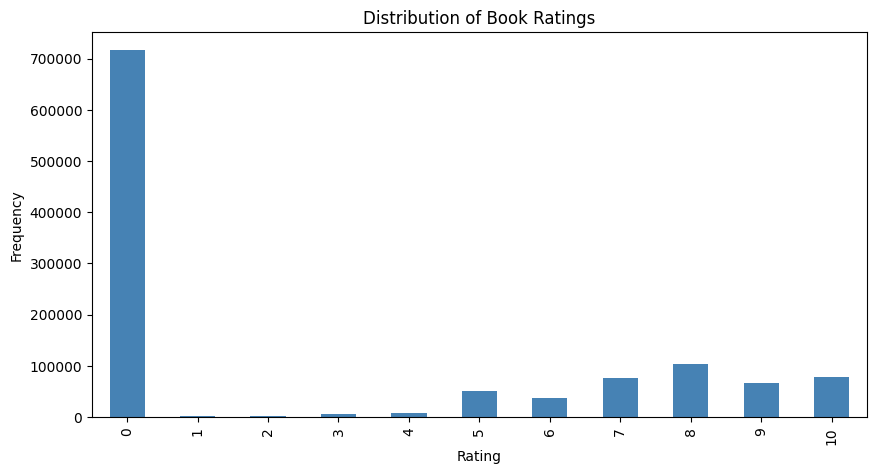

In [12]:
rating_values = pd.to_numeric(
    ratings["Book-Rating"], errors="coerce"
)

print("Rating Distribution:")
print(rating_values.value_counts().sort_index())

print("\nNumber of zero ratings:")
print((rating_values == 0).sum())

rating_values.value_counts().sort_index().plot(
    kind="bar",
    figsize=(10, 5),
    color="steelblue"
)

plt.title("Distribution of Book Ratings")
plt.xlabel("Rating")
plt.ylabel("Frequency")
plt.show()

### Rating Distribution Observation

Out of 1,149,780 ratings, 716,109 (62.28%) are zero
ratings. These represent implicit interactions rather
than explicit user preferences.

In the Silver layer, zero ratings will be removed,
and only ratings between 1 and 10 will be retained.

Age Statistics:
count    168096.000000
mean         34.751434
std          14.428097
min           0.000000
25%          24.000000
50%          32.000000
75%          44.000000
max         244.000000
Name: Age, dtype: float64

Invalid Ages: 1248
Missing Ages: 110762


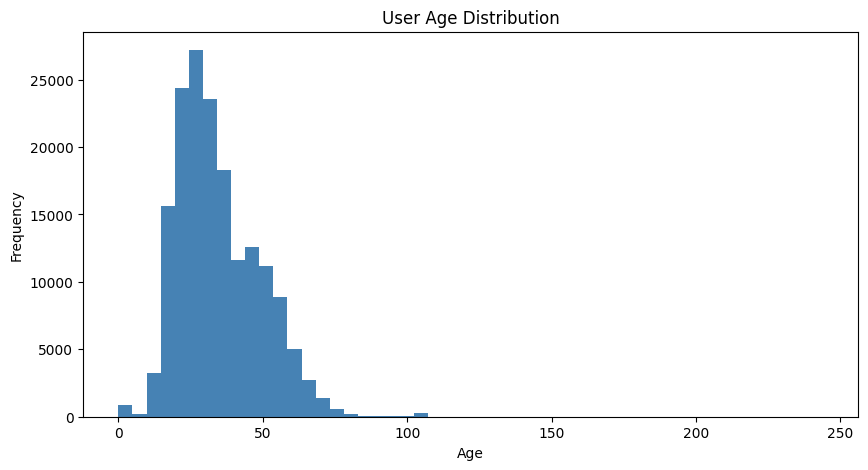

In [14]:
ages = pd.to_numeric(users["Age"], errors="coerce")

print("Age Statistics:")
print(ages.describe())

print("\nInvalid Ages:",
      ((ages < 5) | (ages > 100)).sum())

print("Missing Ages:", ages.isna().sum())

plt.figure(figsize=(10, 5))
plt.hist(ages.dropna(), bins=50, color="steelblue")
plt.title("User Age Distribution")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.show()

Publication Year Statistics:
count    271357.000000
mean       1959.760817
std         257.994226
min           0.000000
25%        1989.000000
50%        1995.000000
75%        2000.000000
max        2050.000000
Name: Year-Of-Publication, dtype: float64

Invalid Publication Years: 4629
Missing Publication Years: 3


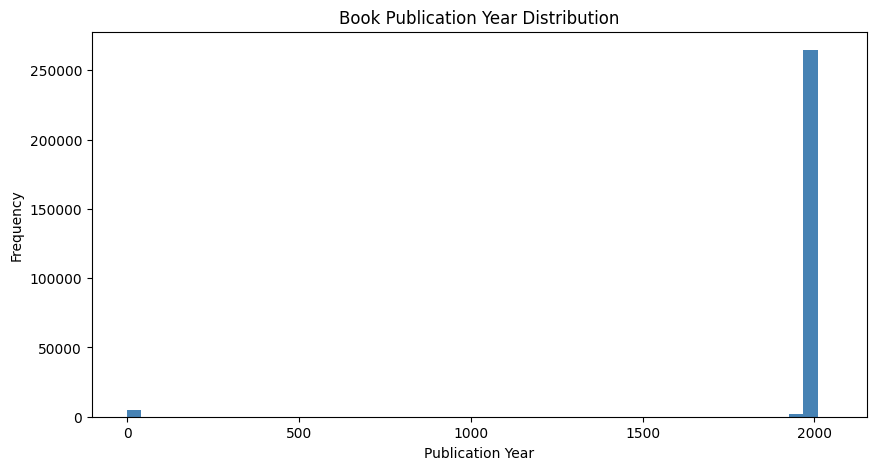

In [13]:
years = pd.to_numeric(
    books["Year-Of-Publication"],
    errors="coerce"
)

current_year = pd.Timestamp.now().year

print("Publication Year Statistics:")
print(years.describe())

print("\nInvalid Publication Years:",
      ((years <= 0) | (years > current_year)).sum())

print("Missing Publication Years:", years.isna().sum())

plt.figure(figsize=(10, 5))
plt.hist(years.dropna(), bins=50, color="steelblue")
plt.title("Book Publication Year Distribution")
plt.xlabel("Publication Year")
plt.ylabel("Frequency")
plt.show()

Ratings per User:
count    105283.000000
mean         10.920851
std          90.562825
min           1.000000
25%           1.000000
50%           1.000000
75%           4.000000
max       13602.000000
dtype: float64

Ratings per Book:
count    340556.000000
mean          3.376185
std          12.436252
min           1.000000
25%           1.000000
50%           1.000000
75%           2.000000
max        2502.000000
dtype: float64

Users with fewer than 10 ratings: 92186
Books with fewer than 10 ratings: 322237

Explicit Ratings per User:
count    77805.000000
mean         5.573819
std         44.001879
min          1.000000
25%          1.000000
50%          1.000000
75%          3.000000
max       8524.000000
dtype: float64

Explicit Ratings per Book:
count    185973.000000
mean          2.331903
std           6.834667
min           1.000000
25%           1.000000
50%           1.000000
75%           2.000000
max         707.000000
dtype: float64


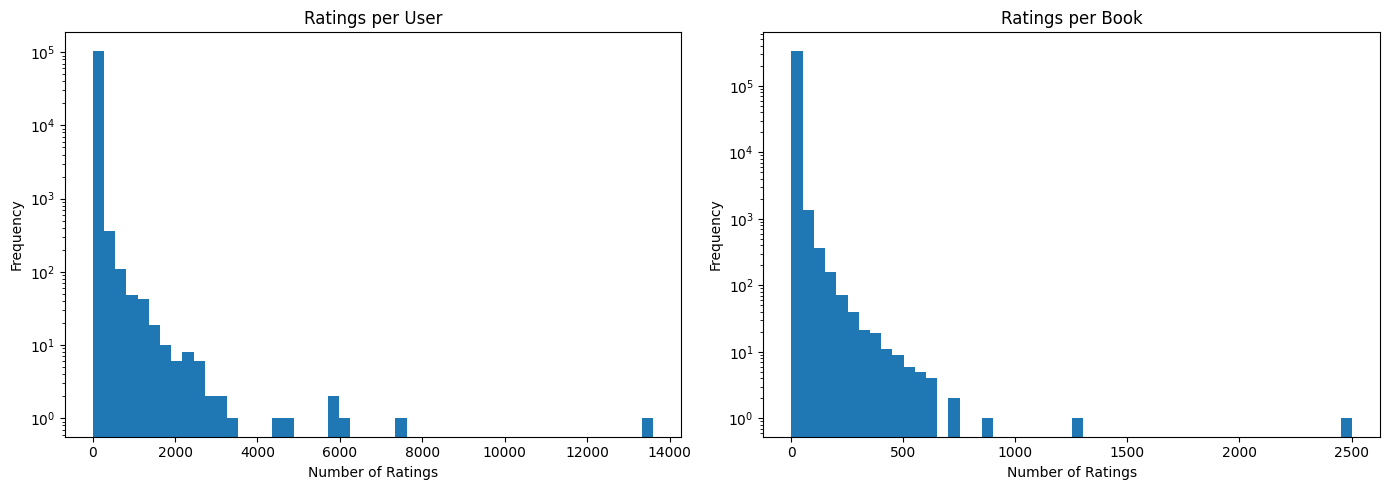

In [15]:
user_counts = ratings.groupby("User-ID").size()
book_counts = ratings.groupby("ISBN").size()

print("Ratings per User:")
print(user_counts.describe())

print("\nRatings per Book:")
print(book_counts.describe())

print("\nUsers with fewer than 10 ratings:",
      (user_counts < 10).sum())

print("Books with fewer than 10 ratings:",
      (book_counts < 10).sum())

explicit = ratings[rating_values.between(1, 10)]

print("\nExplicit Ratings per User:")
print(explicit.groupby("User-ID").size().describe())

print("\nExplicit Ratings per Book:")
print(explicit.groupby("ISBN").size().describe())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(user_counts, bins=50)
axes[0].set_title("Ratings per User")
axes[0].set_xlabel("Number of Ratings")
axes[0].set_ylabel("Frequency")
axes[0].set_yscale("log")

axes[1].hist(book_counts, bins=50)
axes[1].set_title("Ratings per Book")
axes[1].set_xlabel("Number of Ratings")
axes[1].set_ylabel("Frequency")
axes[1].set_yscale("log")

plt.tight_layout()
plt.show()

In [16]:
num_users = users["User-ID"].nunique()
num_books = books["ISBN"].nunique()

valid_pairs = ratings[
    ratings["User-ID"].isin(users["User-ID"]) &
    ratings["ISBN"].isin(books["ISBN"])
]

num_ratings = len(
    valid_pairs[["User-ID", "ISBN"]].drop_duplicates()
)

total_possible = num_users * num_books

density = (num_ratings / total_possible) * 100
sparsity = 100 - density

print("Total Users:", num_users)
print("Total Books:", num_books)
print("Observed User-Book Pairs:", num_ratings)
print("Total Possible User-Book Pairs:", total_possible)

print(f"\nMatrix Density: {density:.6f}%")
print(f"Matrix Sparsity: {sparsity:.6f}%")

Total Users: 278858
Total Books: 271360
Observed User-Book Pairs: 1031136
Total Possible User-Book Pairs: 75670906880

Matrix Density: 0.001363%
Matrix Sparsity: 99.998637%


### EDA Observations

- Dataset structure: The datasets contain 271,360 books,
  278,858 users and 1,149,780 ratings. Missing values
  and duplicate records will be handled in Silver.

- Rating distribution: There are 716,109 zero ratings,
  which will be removed to retain explicit ratings
  between 1 and 10.

- Age and publication year: Invalid ages will be
  replaced with the median age, while invalid
  publication years will be set to null.

- Rating frequency: Most users and books have few
  ratings. A minimum rating threshold will be applied
  to retain meaningful interactions.

- Matrix sparsity: Only 0.001363% of possible user-book
  pairs have recorded interactions, resulting in
  99.998637% sparsity. A sparse matrix will be used
  in the Gold layer.

In [17]:
books = books.drop_duplicates().copy()
users = users.drop_duplicates().copy()
ratings = ratings.drop_duplicates().copy()

print("Duplicate rows removed")

Duplicate rows removed


In [18]:
ratings["Book-Rating"] = pd.to_numeric(
    ratings["Book-Rating"], errors="coerce"
)

ratings = ratings[
    ratings["Book-Rating"].between(1, 10)
].copy()

print("Remaining ratings:", len(ratings))

Remaining ratings: 433671


In [19]:
users["Age"] = pd.to_numeric(
    users["Age"], errors="coerce"
)

users.loc[
    (users["Age"] < 5) | (users["Age"] > 100),
    "Age"
] = np.nan

median_age = users["Age"].median()
users["Age"] = users["Age"].fillna(median_age)

print("Median Age:", median_age)
print("Missing Ages:", users["Age"].isna().sum())

Median Age: 32.0
Missing Ages: 0


In [20]:
location = users["Location"].str.split(
    ",", n=2, expand=True
).reindex(columns=range(3))

users["City"] = location[0].str.strip().str.title()
users["State"] = location[1].str.strip().str.title()
users["Country"] = location[2].str.strip().str.title()

users = users.drop(columns=["Location"])

display(users.head())

,User-ID,Age,ingestion_timestamp,City,State,Country
0,1,32.0,2026-11-25 11:58:26.315965+00:00,Nyc,New York,Usa
1,2,18.0,2026-11-25 11:58:26.315965+00:00,Stockton,California,Usa
2,3,32.0,2026-11-25 11:58:26.315965+00:00,Moscow,Yukon Territory,Russia
3,4,17.0,2026-11-25 11:58:26.315965+00:00,Porto,V.N.Gaia,Portugal
4,5,32.0,2026-11-25 11:58:26.315965+00:00,Farnborough,Hants,United Kingdom


In [21]:
books["Year-Of-Publication"] = pd.to_numeric(
    books["Year-Of-Publication"], errors="coerce"
)

books.loc[
    (books["Year-Of-Publication"] <= 0) |
    (books["Year-Of-Publication"] > pd.Timestamp.now().year),
    "Year-Of-Publication"
] = np.nan

print("Invalid publication years corrected")

Invalid publication years corrected


In [22]:
for col in ["Book-Title", "Book-Author", "Publisher"]:
    books[col] = (
        books[col]
        .str.strip()
        .str.replace(r"\s+", " ", regex=True)
        .str.title()
    )

books = books.drop(columns=[
    "Image-URL-S",
    "Image-URL-M",
    "Image-URL-L"
])

print("Text columns cleaned and image URLs removed")

Text columns cleaned and image URLs removed


In [23]:
ratings = ratings[
    ratings["User-ID"].isin(users["User-ID"]) &
    ratings["ISBN"].isin(books["ISBN"])
].copy()

print("Valid ratings:", len(ratings))

Valid ratings: 383842


In [24]:
MIN_RATINGS = 10

while True:
    previous_size = len(ratings)

    user_counts = ratings["User-ID"].value_counts()
    active_users = user_counts[user_counts >= MIN_RATINGS].index

    ratings = ratings[
        ratings["User-ID"].isin(active_users)
    ]

    book_counts = ratings["ISBN"].value_counts()
    active_books = book_counts[book_counts >= MIN_RATINGS].index

    ratings = ratings[
        ratings["ISBN"].isin(active_books)
    ]

    if len(ratings) == previous_size:
        break

users = users[
    users["User-ID"].isin(ratings["User-ID"])
].copy()

books = books[
    books["ISBN"].isin(ratings["ISBN"])
].copy()

print("Remaining Users:", len(users))
print("Remaining Books:", len(books))
print("Remaining Ratings:", len(ratings))

Remaining Users: 1820
Remaining Books: 2030
Remaining Ratings: 41456


### Minimum Rating Threshold

A minimum threshold of 10 explicit ratings per user
and per book was selected because the EDA showed that
most users and books have very few ratings.

This removes infrequent interactions and retains
sufficient rating information for collaborative filtering.

After filtering, the dataset contains:
- Users: 1,820
- Books: 2,030
- Ratings: 41,456

In [25]:
books.to_parquet("silver/books.parquet", index=False)
users.to_parquet("silver/users.parquet", index=False)
ratings.to_parquet("silver/ratings.parquet", index=False)

print("Silver layer completed successfully")

Silver layer completed successfully


In [26]:
books = pd.read_parquet("silver/books.parquet")
users = pd.read_parquet("silver/users.parquet")
ratings = pd.read_parquet("silver/ratings.parquet")

In [27]:
user_ids = sorted(ratings["User-ID"].unique())
book_ids = sorted(ratings["ISBN"].unique())

user_to_idx = {
    user: i for i, user in enumerate(user_ids)
}

book_to_idx = {
    book: i for i, book in enumerate(book_ids)
}

matrix_ratings = ratings.groupby(
    ["User-ID", "ISBN"], as_index=False
)["Book-Rating"].mean()

row_indices = matrix_ratings["User-ID"].map(user_to_idx)
col_indices = matrix_ratings["ISBN"].map(book_to_idx)

rating_matrix = csr_matrix(
    (
        matrix_ratings["Book-Rating"],
        (row_indices, col_indices)
    ),
    shape=(len(user_ids), len(book_ids))
)

save_npz("gold/rating_matrix.npz", rating_matrix)

print("Matrix Shape:", rating_matrix.shape)
print("Non-zero Entries:", rating_matrix.nnz)

Matrix Shape: (1820, 2030)
Non-zero Entries: 41456


In [28]:
book_lookup = pd.DataFrame({
    "ISBN": book_ids,
    "book_index": range(len(book_ids))
})

book_lookup = book_lookup.merge(
    books[["ISBN", "Book-Title", "Book-Author"]],
    on="ISBN",
    how="left"
)

book_lookup.to_parquet(
    "gold/book_lookup.parquet", index=False
)

user_lookup = pd.DataFrame({
    "User-ID": user_ids,
    "user_index": range(len(user_ids))
})

user_lookup.to_parquet(
    "gold/user_lookup.parquet", index=False
)

display(book_lookup.head())

,ISBN,book_index,Book-Title,Book-Author
0,0020199600,0,Great Gatsby (Reissue),F. Scott Fitzgerald
1,0020442203,1,"Lion, The Witch And The Wardrobe",C.S. Lewis
2,002542730X,2,Politically Correct Bedtime Stories: Modern Ta...,James Finn Garner
3,0028604199,3,Once Upon A More Enlightened Time: More Politi...,James Finn Garner
4,0060002050,4,On A Wicked Dawn (Cynster Novels),Stephanie Laurens


In [29]:
user_aggregates = ratings.groupby("User-ID").agg(
    average_rating=("Book-Rating", "mean"),
    rating_count=("Book-Rating", "count")
).reset_index()

user_aggregates.to_parquet(
    "gold/user_aggregates.parquet", index=False
)

display(user_aggregates.head())

,User-ID,average_rating,rating_count
0,100088,9.384615,13
1,100227,9.000000,13
2,100264,7.916667,12
3,10030,9.400000,10
4,100459,8.369565,46


In [30]:
book_aggregates = ratings.groupby("ISBN").agg(
    average_rating=("Book-Rating", "mean"),
    rating_count=("Book-Rating", "count")
).reset_index()

book_aggregates.to_parquet(
    "gold/book_aggregates.parquet", index=False
)

display(book_aggregates.head())

print("Gold layer completed successfully")

,ISBN,average_rating,rating_count
0,0020199600,8.166667,12
1,0020442203,8.833333,12
2,002542730X,7.481481,27
3,0028604199,7.900000,10
4,0060002050,7.545455,11


Gold layer completed successfully


In [31]:
rating_matrix = load_npz("gold/rating_matrix.npz")

book_lookup = pd.read_parquet(
    "gold/book_lookup.parquet"
).sort_values("book_index").reset_index(drop=True)

user_lookup = pd.read_parquet(
    "gold/user_lookup.parquet"
)

user_to_idx = dict(zip(
    user_lookup["User-ID"],
    user_lookup["user_index"]
))

book_user_matrix = rating_matrix.T.tocsr()

print("Book-User Matrix:", book_user_matrix.shape)

Book-User Matrix: (2030, 1820)


In [32]:
model = NearestNeighbors(
    metric="cosine",
    algorithm="brute"
)

model.fit(book_user_matrix)

print("Cosine similarity model ready")

Cosine similarity model ready


In [34]:
def similar_books(book_title):

    matches = book_lookup[
        book_lookup["Book-Title"].str.lower()
        == book_title.strip().lower()
    ]

    if matches.empty:
        return "Book not found"

    book_idx = int(matches.iloc[0]["book_index"])

    distances, indices = model.kneighbors(
        book_user_matrix[book_idx],
        n_neighbors=11
    )

    results = []

    for distance, idx in zip(distances[0], indices[0]):

        if idx == book_idx:
            continue

        results.append({
            "Book-Title": book_lookup.iloc[idx]["Book-Title"],
            "Similarity": round(1 - distance, 4)
        })

    return pd.DataFrame(results[:10])

In [35]:
sample_book = book_lookup.iloc[0]["Book-Title"]

print("Selected Book:", sample_book)

display(similar_books(sample_book))

Selected Book: Great Gatsby (Reissue)


,Book-Title,Similarity
0,Name Of The Rose-Nla,0.2699
1,The Cereal Murders,0.1974
2,"The Subtle Knife (His Dark Materials, Book 2)",0.1898
3,The Little Prince,0.1499
4,The Outsiders,0.1479
5,Devil'S Waltz (Alex Delaware Novels (Paperback)),0.1370
6,Fast Food Nation: The Dark Side Of The All-Ame...,0.1338
7,The Crucible: A Play In Four Acts (Penguin Plays),0.1330
8,The Book Borrower: A Novel,0.1317
9,A Widow For One Year,0.1278


In [36]:
def recommend(user_id, n=10):

    user_id = str(user_id)

    if user_id not in user_to_idx:
        return "User not found"

    user_idx = user_to_idx[user_id]

    user_ratings = rating_matrix.getrow(user_idx)

    rated_books = user_ratings.indices
    rating_values = user_ratings.data

    already_read = set(rated_books)

    liked_books = [
        (idx, rating)
        for idx, rating in zip(rated_books, rating_values)
        if rating >= 8
    ]

    scores = defaultdict(float)

    for book_idx, rating in liked_books:

        distances, indices = model.kneighbors(
            book_user_matrix[book_idx],
            n_neighbors=51
        )

        for distance, idx in zip(
            distances[0], indices[0]
        ):

            if idx in already_read:
                continue

            similarity = 1 - distance

            if similarity > 0:
                scores[idx] += similarity * rating

    ranked_books = sorted(
        scores.items(),
        key=lambda x: x[1],
        reverse=True
    )

    results = []

    seen_titles = set(
        book_lookup.iloc[list(already_read)]["Book-Title"]
    )

    for idx, score in ranked_books:

        title = book_lookup.iloc[idx]["Book-Title"]

        if title in seen_titles:
            continue

        seen_titles.add(title)

        results.append({
            "Book-Title": title,
            "Score": round(score, 4)
        })

        if len(results) == n:
            break

    return pd.DataFrame(results)

In [37]:
test_users = (
    ratings[ratings["Book-Rating"] >= 8]
    ["User-ID"]
    .value_counts()
    .head(3)
    .index
    .tolist()
)

print("Selected Users:", test_users)

Selected Users: ['11676', '104636', '153662']


In [38]:
for user_id in test_users:

    print("\n" + "=" * 60)
    print("USER ID:", user_id)
    print("=" * 60)

    liked_books = ratings[
        (ratings["User-ID"] == user_id) &
        (ratings["Book-Rating"] >= 8)
    ]

    liked_books = liked_books.merge(
        book_lookup[["ISBN", "Book-Title"]],
        on="ISBN"
    )

    liked_books = liked_books[
        ["Book-Title", "Book-Rating"]
    ].sort_values("Book-Rating", ascending=False)

    print("\nHighly Rated Books:")
    display(liked_books.head(10))

    print("\nTop 10 Recommended Books:")
    display(recommend(user_id, n=10))


USER ID: 11676

Highly Rated Books:


,Book-Title,Book-Rating
606,The Time Traveler'S Wife (Today Show Book Club...,10
605,The Time Traveler'S Wife,10
603,Tipping The Velvet,10
2,The Poisonwood Bible,10
3,Daughter Of Fortune : A Novel (Oprah'S Book Cl...,10
4,Prodigal Summer,10
602,The Color Of Water: A Black Man'S Tribute To H...,10
6,I Know This Much Is True (Oprah'S Book Club),10
581,Soul Harvest: The World Takes Sides (Left Behi...,10
579,Tribulation Force: The Continuing Drama Of Tho...,10



Top 10 Recommended Books:


,Book-Title,Score
0,"Night Shield (Intimate Moments, 1027)",66.3380
1,Public Secrets,63.6049
2,Palomino,57.2102
3,Birthright,54.7463
4,Night Tales,52.3481
5,Tears Of The Moon (Irish Trilogy),49.7638
6,Stanislaski Brothers (Silhouette Promo),48.3582
7,Perfect,46.5948
8,Conspiracy In Death,46.0116
9,A Perfect Stranger,44.7076



USER ID: 104636

Highly Rated Books:


,Book-Title,Book-Rating
0,Where The Sidewalk Ends : Poems And Drawings,10
4,Little House On The Prairie,10
9,Charlotte'S Web (Trophy Newbery),10
11,"The Lion, The Witch, And The Wardrobe (The Chr...",10
10,Bridge To Terabithia,10
42,Secrets,10
36,Harry Potter And The Prisoner Of Azkaban (Book 3),10
32,Talk Before Sleep,10
37,Harry Potter And The Goblet Of Fire (Book 4),10
35,Harry Potter And The Chamber Of Secrets (Book 2),10


... (2 outputs left out)


USER ID: 153662

Highly Rated Books:


,Book-Title,Book-Rating
0,The Divine Secrets Of The Ya-Ya Sisterhood: A ...,10
5,The Secret Garden,10
3,The Perfect Storm : A True Story Of Men Agains...,10
15,Pope Joan (Ballantine Reader'S Circle),10
16,Killjoy,10
9,I Capture The Castle,10
8,Slammerkin,10
14,The Killer Angels,10
13,Fahrenheit 451,10
12,The Fellowship Of The Ring (The Lord Of The Ri...,10



Top 10 Recommended Books:


,Book-Title,Score
0,Born In Shame,75.6290
1,Night Tales,71.5277
2,The Macgregors: Serena - Caine (The Macgregors),62.1591
3,Loyalty In Death,58.6323
4,Considering Kate (The Stanislaskis) (Silhouett...,54.4270
5,The Villa,53.9019
6,Paradise,51.1715
7,Ceremony In Death (Eve Dallas Mysteries (Paper...,49.1265
8,The Macgregors: Alan - Grant (The Macgregors),47.8597
9,When The Storm Breaks,47.2351


In [39]:
for user_id in test_users:

    recommendations = recommend(user_id, n=10)

    rated_isbns = ratings[
        ratings["User-ID"] == user_id
    ]["ISBN"]

    rated_titles = set(
        book_lookup[
            book_lookup["ISBN"].isin(rated_isbns)
        ]["Book-Title"]
    )

    recommended_titles = set(
        recommendations["Book-Title"]
    )

    overlap = rated_titles.intersection(
        recommended_titles
    )

    assert len(overlap) == 0
    assert len(recommendations) == 10

    print(f"User {user_id}: Sanity check passed")

User 11676: Sanity check passed
User 104636: Sanity check passed
User 153662: Sanity check passed
